# Model 1 — can my own profile predict my decision?

**Task:** binary classification of `dec` ("would I like to see this partner again?") from **my own sign-up
questionnaire only**: gender, age, race, field of study, career, goal, dating habits, 17 activities,
what I look for in a partner (100 points) and how I rate myself.

Nothing about the partner or the date itself is used, so the model can only learn how "picky" a type of
person is.

**Evaluation — leave-one-wave-out cross-validation.** The data comes from 21 separate events (waves).
Every model is trained on 20 waves and tested on the remaining one, 21 times. The same person never
appears in both the training and the test data, and every test wave is a new event the model has never
seen. One-hot encoding and scaling are fitted inside every fold on the training waves only.

**Metrics:** accuracy, F1 for the "yes" class, ROC AUC. A majority-class baseline (always "no") shows what
accuracy is worth nothing.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt

from speed_dating.data import RESULTS_DIR, load_data
from speed_dating.evaluation import evaluate, plot_per_wave, plot_train_test, test_summary
from speed_dating.features import build_dataset

df = load_data()
X, y, waves = build_dataset(df, target="dec", feature_set="own_profile")
print(f"{len(X)} dates, {X.shape[1]} features, share of 'yes': {y.mean():.1%}")

8132 dates, 38 features, share of 'yes': 42.3%


In [2]:
results = evaluate(X, y, waves)
results.to_csv(RESULTS_DIR / "model_own_profile.csv", index=False)
test_summary(results)

metric,Accuracy,F1,ROC AUC
model,,,
Majority baseline,0.560 ± 0.058,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.581 ± 0.063,0.428 ± 0.122,0.596 ± 0.074
Gaussian NB,0.486 ± 0.046,0.558 ± 0.062,0.541 ± 0.051
SVM (linear),0.572 ± 0.068,0.415 ± 0.117,0.590 ± 0.082
KNN (k=89),0.568 ± 0.066,0.352 ± 0.121,0.560 ± 0.068
Random Forest,0.571 ± 0.067,0.244 ± 0.124,0.582 ± 0.075


Mean ± standard deviation over the 21 test waves.

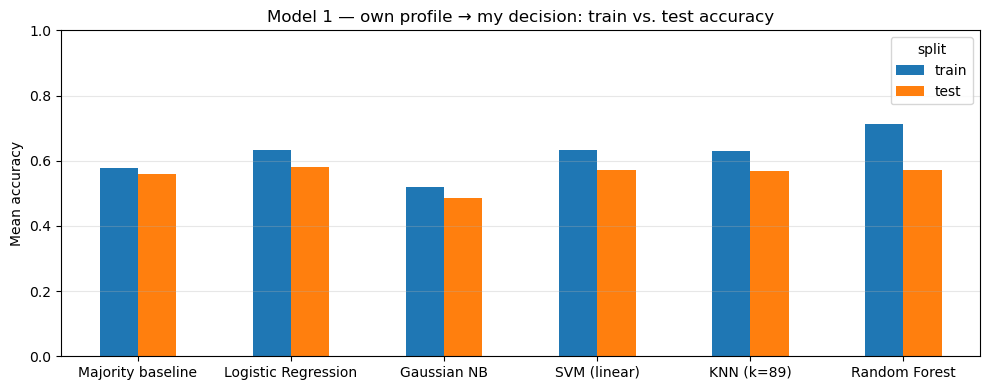

In [3]:
plot_train_test(results, title="Model 1 — own profile → my decision: train vs. test accuracy")
plt.show()

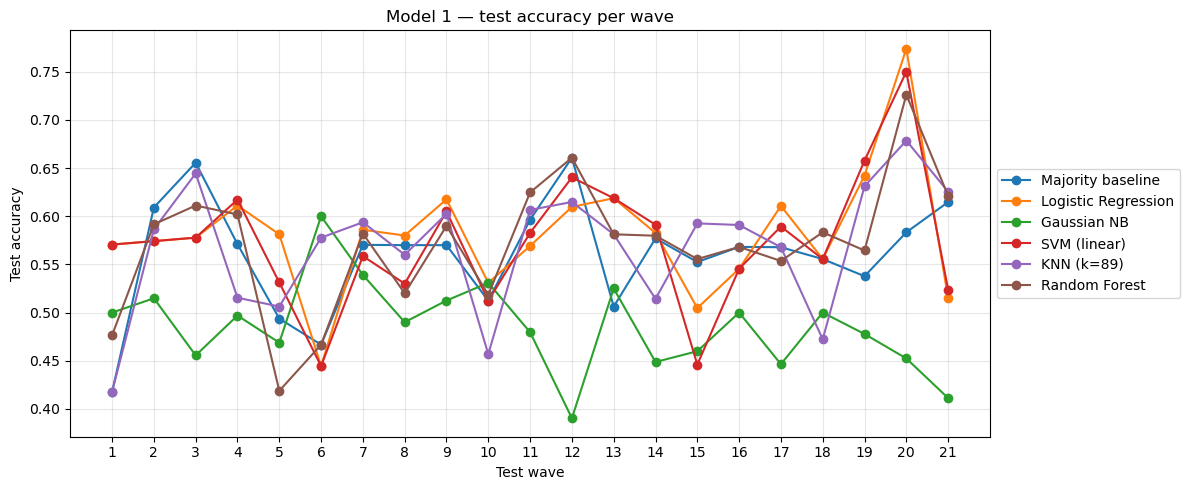

In [4]:
plot_per_wave(results, title="Model 1 — test accuracy per wave")
plt.show()

## Conclusions

* **The own profile alone hardly predicts the decision.** The best model (logistic regression) reaches
  58% accuracy against 56% for always answering "no", and ROC AUC 0.60, where 0.5 is a random guess.
* All models score higher on the training waves (63–71%) than on the test wave (57–58%), the random
  forest most of all: they partly memorize individual participants, which does not transfer to a new event.
* Gaussian Naive Bayes is below the baseline in accuracy: its independence assumption does not hold for
  correlated questionnaire answers, and it says "yes" too often (hence its higher F1).
* The accuracy varies a lot between waves (±6%): how picky the participants of one event are cannot be
  learned from the other events.

Whether I say "yes" depends on **who the partner is and how the date went**, not on who I am — which is
what Models 2 and 3 add.